# Uyku Verimliliği: Tahmin ve Yaşam Tarzı Etkileri

**Veri:** 452 katılımcının bir gecelik uyku kaydı (Sleep Efficiency, Kaggle).
Hedef değişken `Sleep efficiency`: yatakta geçen sürenin ne kadarının uykuyla geçtiği (0–1).

Bu notebook iki farklı soruya cevap arıyor ve bu iki soru farklı yöntemler gerektiriyor:

1. **Tahmin:** Elimizdeki tüm ölçümlerle uyku verimliliğini ne kadar iyi tahmin edebiliriz, hangi model en iyisi?
   Burada amaç genelleme hatasını dürüst ölçmek: tüm ön işleme pipeline içinde, model seçimi nested CV ile, test seti tek sefer.
2. **Açıklama:** Kafein, alkol, sigara ve egzersiz uyku verimliliğiyle nasıl ilişkili?
   Derin uyku, REM ve uyanma sayısı aynı gece ölçülüyor; bunlar yaşam tarzının *sonucu* olabilecek ara değişkenler.
   Bu yüzden yaşam tarzı etkilerini yorumlamak için ayrı bir açıklayıcı model (OLS, robust standart hata) kuruyorum.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan

from sklearn.model_selection import (train_test_split, KFold, RepeatedKFold,
                                     GridSearchCV, cross_validate)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor

SEED = 42
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

def kaydet(ad):
    plt.savefig(f'figures/{ad}.png', dpi=150, bbox_inches='tight')

## 1. Veri ve kalite kontrolleri

In [2]:
ham = pd.read_csv('data/Sleep_Efficiency.csv', parse_dates=['Bedtime', 'Wakeup time'])
print(ham.shape)
print('Tekil ID:', ham['ID'].nunique())
ham.head()

(452, 15)
Tekil ID: 452


,ID,Age,Gender,Bedtime,Wakeup time,Sleep duration,Sleep efficiency,REM sleep percentage,Deep sleep percentage,Light sleep percentage,Awakenings,Caffeine consumption,Alcohol consumption,Smoking status,Exercise frequency
0,1,65,Female,2021-03-06 01:00:00,2021-03-06 07:00:00,6.0000,0.8800,18,70,12,0.0000,0.0000,0.0000,Yes,3.0000
1,2,69,Male,2021-12-05 02:00:00,2021-12-05 09:00:00,7.0000,0.6600,19,28,53,3.0000,0.0000,3.0000,Yes,3.0000
2,3,40,Female,2021-05-25 21:30:00,2021-05-25 05:30:00,8.0000,0.8900,20,70,10,1.0000,0.0000,0.0000,No,3.0000
3,4,40,Female,2021-11-03 02:30:00,2021-11-03 08:30:00,6.0000,0.5100,23,25,52,3.0000,50.0000,5.0000,Yes,1.0000
4,5,57,Male,2021-03-13 01:00:00,2021-03-13 09:00:00,8.0000,0.7600,27,55,18,3.0000,0.0000,3.0000,No,3.0000


In [3]:
ham.describe().T

,count,mean,min,25%,50%,75%,max,std
ID,452.0000,226.5000,1.0000,113.7500,226.5000,339.2500,452.0000,130.6254
Age,452.0000,40.2854,9.0000,29.0000,40.0000,52.0000,69.0000,13.1722
Bedtime,452,2021-07-13 00:03:39.026548480,2021-01-03 00:30:00,2021-04-14 01:07:30,2021-07-20 23:30:00,2021-10-11 05:22:30,2021-12-31 21:00:00,NaN
Wakeup time,452,2021-07-12 20:19:22.831858176,2021-01-03 08:30:00,2021-04-14 07:52:30,2021-07-20 16:00:00,2021-10-11 05:52:30,2021-12-31 06:30:00,NaN
Sleep duration,452.0000,7.4657,5.0000,7.0000,7.5000,8.0000,10.0000,0.8666
Sleep efficiency,452.0000,0.7889,0.5000,0.6975,0.8200,0.9000,0.9900,0.1352
REM sleep percentage,452.0000,22.6150,15.0000,20.0000,22.0000,25.0000,30.0000,3.5260
Deep sleep percentage,452.0000,52.8230,18.0000,48.2500,58.0000,63.0000,75.0000,15.6542
Light sleep percentage,452.0000,24.5619,7.0000,15.0000,18.0000,32.5000,63.0000,15.3137
Awakenings,432.0000,1.6412,0.0000,1.0000,1.0000,3.0000,4.0000,1.3568


Modele girmeden önce üç şeyi kontrol ettim:

- **REM + Derin + Hafif uyku yüzdeleri her satırda tam 100.** Bu üç değişken birlikte modele girerse tam çoklu doğrusallık oluşur
  (VIF sonsuz). Derin ve hafif uyku arasındaki −0.97'lik korelasyonun asıl sebebi bu kompozisyon kısıtı. Hafif uykuyu referans olarak dışarıda bırakıyorum. Böylece derin uyku katsayısı "1 puanlık hafif uykunun derin uykuya kayması" olarak okunuyor.
- **`Wakeup time` tarihinde hata var:** gece yarısından önce yatanlarda kalkış tarihi bir gün geri yazılmış (fark tam −24 saat).
  Saat bilgisi doğru, bu yüzden `Bedtime`'dan yalnızca yatış saatini türettim. Kalkış saati, yatış + süre ile zaten belirli.
- **Eksik değerler** dört değişkende var (%1–6). Eksik olan ve olmayan grupların hedef ortalamaları yakın; eksikliğin hedefle güçlü bir ilişkisi görünmüyor.

In [4]:
toplam = ham[['REM sleep percentage', 'Deep sleep percentage', 'Light sleep percentage']].sum(axis=1)
print('REM + Derin + Hafif dağılımı:', toplam.value_counts().to_dict())

fark = (ham['Wakeup time'] - ham['Bedtime']).dt.total_seconds() / 3600 - ham['Sleep duration']
print('(Kalkış - Yatış) - Süre farkı (saat):', fark.round(2).value_counts().to_dict())

eksik = ham.isna().sum()
eksik = eksik[eksik > 0].to_frame('eksik_sayi')
eksik['oran_%'] = 100 * eksik['eksik_sayi'] / len(ham)
eksik['hedef_ort_eksik'] = [ham.loc[ham[c].isna(), 'Sleep efficiency'].mean() for c in eksik.index]
eksik['hedef_ort_dolu'] = [ham.loc[ham[c].notna(), 'Sleep efficiency'].mean() for c in eksik.index]
eksik['mann_whitney_p'] = [stats.mannwhitneyu(ham.loc[ham[c].isna(), 'Sleep efficiency'],
                                              ham.loc[ham[c].notna(), 'Sleep efficiency']).pvalue
                           for c in eksik.index]
eksik

REM + Derin + Hafif dağılımı: {100: 452}
(Kalkış - Yatış) - Süre farkı (saat): {0.0: 241, -24.0: 211}


,eksik_sayi,oran_%,hedef_ort_eksik,hedef_ort_dolu,mann_whitney_p
Awakenings,20,4.4248,0.7915,0.7888,0.9086
Caffeine consumption,25,5.5310,0.7776,0.7896,0.7187
Alcohol consumption,14,3.0973,0.7929,0.7888,0.9263
Exercise frequency,6,1.3274,0.7717,0.7891,0.5753


In [5]:
df = ham.copy()
saat = df['Bedtime'].dt.hour + df['Bedtime'].dt.minute / 60
df['Bedtime hour'] = np.where(saat < 12, saat + 24, saat)   # 01:00 -> 25, gece yarısını süreklilik içinde tutmak için
df = df.drop(columns=['ID', 'Bedtime', 'Wakeup time', 'Light sleep percentage'])

HEDEF = 'Sleep efficiency'
UYKU_YAPISI = ['REM sleep percentage', 'Deep sleep percentage', 'Awakenings']
YASAM = ['Caffeine consumption', 'Alcohol consumption', 'Exercise frequency', 'Smoking status']
DEMOGRAFIK = ['Age', 'Gender']
ZAMAN = ['Sleep duration', 'Bedtime hour']

KATEGORIK = ['Gender', 'Smoking status']
SAYISAL = [c for c in df.columns if c not in KATEGORIK + [HEDEF]]
print('Sayısal :', SAYISAL)
print('Kategorik:', KATEGORIK)

Sayısal : ['Age', 'Sleep duration', 'REM sleep percentage', 'Deep sleep percentage', 'Awakenings', 'Caffeine consumption', 'Alcohol consumption', 'Exercise frequency', 'Bedtime hour']
Kategorik: ['Gender', 'Smoking status']


## 2. Keşifsel analiz

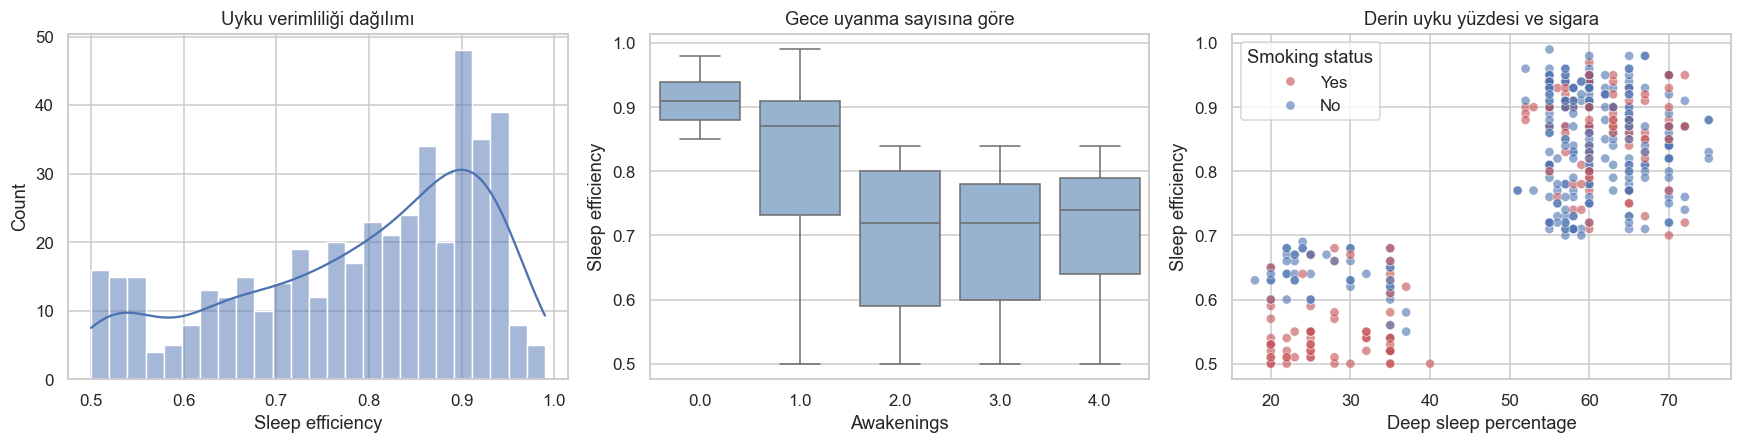

Çarpıklık: -0.648


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
sns.histplot(df[HEDEF], bins=25, kde=True, ax=axes[0], color='#4C72B0')
axes[0].set_title('Uyku verimliliği dağılımı')
sns.boxplot(data=df, x='Awakenings', y=HEDEF, ax=axes[1], color='#8fb3d9')
axes[1].set_title('Gece uyanma sayısına göre')
sns.scatterplot(data=df, x='Deep sleep percentage', y=HEDEF, hue='Smoking status',
                alpha=0.6, ax=axes[2], palette={'Yes': '#C44E52', 'No': '#4C72B0'})
axes[2].set_title('Derin uyku yüzdesi ve sigara')
plt.tight_layout(); kaydet('eda_hedef'); plt.show()

print(f"Çarpıklık: {stats.skew(df[HEDEF]):.3f}")

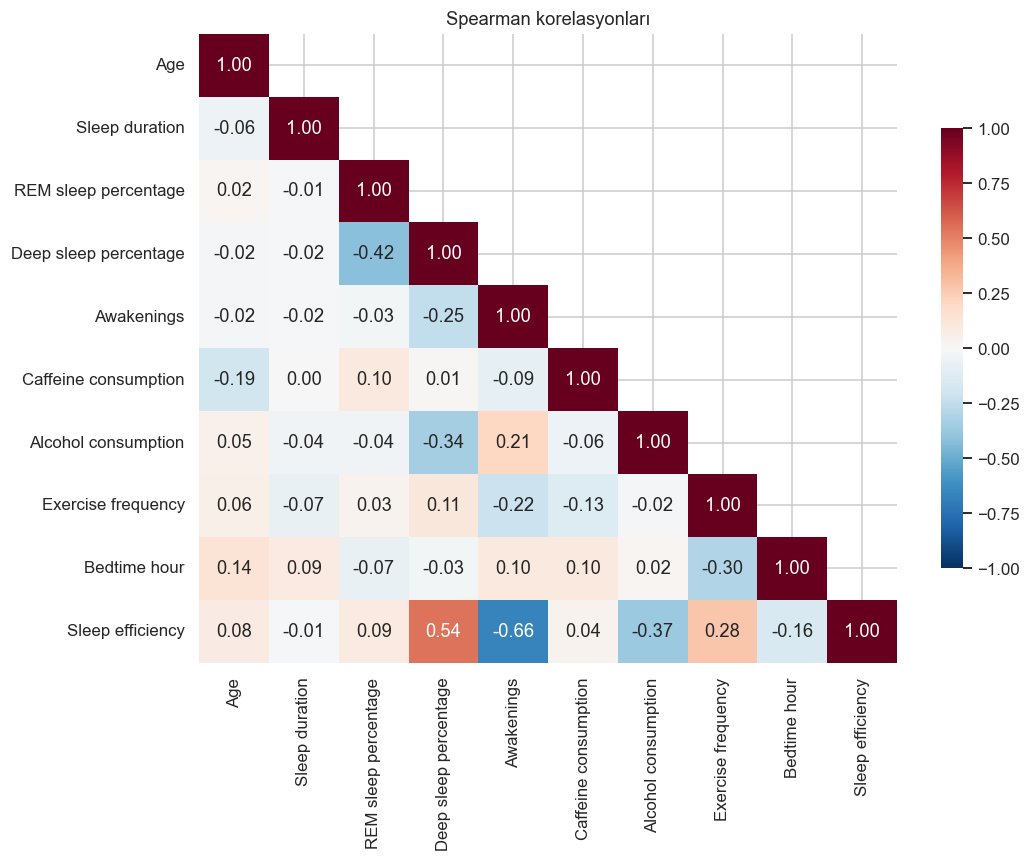

In [7]:
korelasyon = df[SAYISAL + [HEDEF]].corr(method='spearman')
plt.figure(figsize=(10, 8))
maske = np.triu(np.ones_like(korelasyon, dtype=bool), k=1)
sns.heatmap(korelasyon, mask=maske, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1,
            cbar_kws={'shrink': .7})
plt.title('Spearman korelasyonları')
plt.tight_layout(); kaydet('korelasyon'); plt.show()

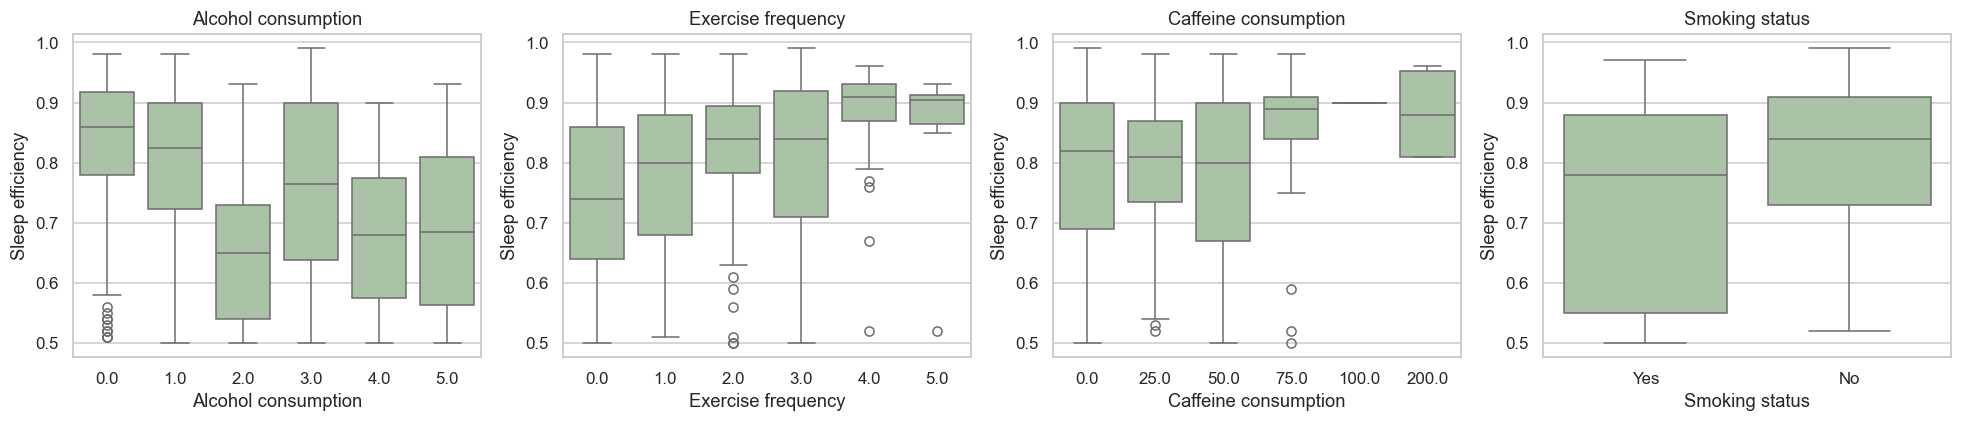

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, ['Alcohol consumption', 'Exercise frequency', 'Caffeine consumption', 'Smoking status']):
    sns.boxplot(data=df, x=c, y=HEDEF, ax=ax, color='#a7c7a0')
    ax.set_title(c)
plt.tight_layout(); kaydet('eda_yasam_tarzi'); plt.show()

**EDA notları**

- Hedef sola çarpık ve 0.5–0.99 aralığında sınırlı. Bu yüzden doğrusal modelde artıkların sabit varyanslı olmasını beklemiyorum;
  açıklayıcı modelde heteroskedastisiteye dayanıklı (HC3) standart hata kullanacağım.
- Derin uyku ile verimlilik arasında güçlü pozitif, uyanma sayısıyla güçlü negatif ilişki var.
- Alkol arttıkça ve sigara içenlerde verimlilik düşüyor, egzersiz sıklığı arttıkça yükseliyor. Bunlar ham ilişkiler,
  yaş ve diğer değişkenler kontrol edilmeden yorumlanmamalı (Bölüm 7).

## 3. Eğitim / test ayrımı ve ön işleme

Test seti (%20) en başta ayrılıyor ve yalnızca en sonda bir kez kullanılıyor.
Eksik değer doldurma ve ölçekleme `Pipeline` içinde; yani CV'nin her katında medyan ve ölçek yalnızca o katın eğitim kısmından öğreniliyor.

In [9]:
X = df.drop(columns=HEDEF)
y = df[HEDEF]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED)
print(f'Eğitim: {X_train.shape}, Test: {X_test.shape}')

def on_isleme(olcekle):
    sayisal_adimlar = [('impute', SimpleImputer(strategy='median'))]
    if olcekle:
        sayisal_adimlar.append(('scale', StandardScaler()))
    return ColumnTransformer([
        ('num', Pipeline(sayisal_adimlar), SAYISAL),
        ('cat', OneHotEncoder(drop='if_binary'), KATEGORIK),
    ])

Eğitim: (361, 11), Test: (91, 11)


## 4. Modeller ve nested cross-validation

Yedi model aynı koşullarda karşılaştırılıyor. Hiperparametresi olan modeller iç döngüde (5 katlı CV) ayarlanıyor,
ayarlama sürecinin tamamı dış döngüde (5 kat × 3 tekrar = 15 bölünme) değerlendiriliyor.
Bu sayede "en iyi parametreyi seçtiğim veriyle aynı veride performans ölçme" iyimserliği ortadan kalkıyor.

In [10]:
ic_cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
dis_cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=SEED)

def ayarla(model, grid=None, olcekle=False):
    pipe = Pipeline([('pre', on_isleme(olcekle)), ('model', model)])
    if grid is None:
        return pipe
    grid = {f'model__{k}': v for k, v in grid.items()}
    return GridSearchCV(pipe, grid, cv=ic_cv, scoring='neg_root_mean_squared_error', n_jobs=-1)

modeller = {
    'Doğrusal Regresyon': ayarla(LinearRegression(), olcekle=True),
    'KNN': ayarla(KNeighborsRegressor(), {'n_neighbors': list(range(3, 31, 2)),
                                          'weights': ['uniform', 'distance']}, olcekle=True),
    'Karar Ağacı': ayarla(DecisionTreeRegressor(random_state=SEED)),
    'Budanmış Ağaç': ayarla(DecisionTreeRegressor(random_state=SEED),
                            {'ccp_alpha': np.r_[0, np.logspace(-5, -2, 16)]}),
    'Bagging': ayarla(BaggingRegressor(DecisionTreeRegressor(), n_estimators=300, random_state=SEED, n_jobs=-1)),
    'Random Forest': ayarla(RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1),
                            {'max_features': [0.33, 0.5, 1.0], 'min_samples_leaf': [1, 3, 5]}),
    'XGBoost': ayarla(XGBRegressor(subsample=0.8, colsample_bytree=0.8, random_state=SEED, n_jobs=1, verbosity=0),
                      {'n_estimators': [200, 500], 'max_depth': [2, 3, 4],
                       'learning_rate': [0.03, 0.1], 'min_child_weight': [1, 5]}),
}

In [11]:
cv_sonuc = {}
for ad, model in modeller.items():
    r = cross_validate(model, X_train, y_train, cv=dis_cv, n_jobs=-1 if ad != 'Random Forest' else 2,
                       scoring={'rmse': 'neg_root_mean_squared_error', 'r2': 'r2'})
    cv_sonuc[ad] = {'rmse': -r['test_rmse'], 'r2': r['test_r2']}
    print(f"{ad:<20} RMSE = {cv_sonuc[ad]['rmse'].mean():.4f} ± {cv_sonuc[ad]['rmse'].std():.4f}   "
          f"R² = {cv_sonuc[ad]['r2'].mean():.3f} ± {cv_sonuc[ad]['r2'].std():.3f}")

Doğrusal Regresyon   RMSE = 0.0617 ± 0.0048   R² = 0.784 ± 0.041


KNN                  RMSE = 0.0650 ± 0.0056   R² = 0.761 ± 0.046
Karar Ağacı          RMSE = 0.0680 ± 0.0093   R² = 0.734 ± 0.080


Budanmış Ağaç        RMSE = 0.0520 ± 0.0061   R² = 0.845 ± 0.046


Bagging              RMSE = 0.0508 ± 0.0062   R² = 0.852 ± 0.041


Random Forest        RMSE = 0.0500 ± 0.0055   R² = 0.857 ± 0.035


XGBoost              RMSE = 0.0503 ± 0.0057   R² = 0.856 ± 0.035


### Farklar istatistiksel olarak anlamlı mı?

CV katları birbirinden bağımsız değil (eğitim kümeleri büyük ölçüde örtüşüyor), bu yüzden katlar üzerinde düz bir eşleştirilmiş
t-testi varyansı küçümser ve gereğinden çok "anlamlı" sonuç üretir. Nadeau & Bengio (2003) düzeltmesini kullanıyorum:
varyans terimi $\left(\frac{1}{J} + \frac{n_{test}}{n_{train}}\right)$ ile ölçekleniyor.

In [12]:
def duzeltilmis_t_testi(a, b, n_train, n_test):
    d = np.asarray(a) - np.asarray(b)
    J = len(d)
    var = np.var(d, ddof=1) * (1 / J + n_test / n_train)
    t = d.mean() / np.sqrt(var)
    p = 2 * stats.t.sf(abs(t), df=J - 1)
    return d.mean(), t, p

n_tr = int(len(X_train) * 4 / 5); n_te = len(X_train) - n_tr
tablo = pd.DataFrame({ad: {'CV RMSE': v['rmse'].mean(), 'RMSE std': v['rmse'].std(),
                           'CV R²': v['r2'].mean()} for ad, v in cv_sonuc.items()}).T
tablo = tablo.sort_values('CV RMSE')
en_iyi = tablo.index[0]
tablo['Fark (en iyiye göre)'] = np.nan
tablo['p (düzeltilmiş t)'] = np.nan
for ad in tablo.index[1:]:
    fark, t, p = duzeltilmis_t_testi(cv_sonuc[ad]['rmse'], cv_sonuc[en_iyi]['rmse'], n_tr, n_te)
    tablo.loc[ad, ['Fark (en iyiye göre)', 'p (düzeltilmiş t)']] = fark, p
print('CV ile en iyi model:', en_iyi)
tablo

CV ile en iyi model: Random Forest


,CV RMSE,RMSE std,CV R²,Fark (en iyiye göre),p (düzeltilmiş t)
Random Forest,0.0500,0.0055,0.8571,NaN,NaN
XGBoost,0.0503,0.0057,0.8556,0.0003,0.8044
Bagging,0.0508,0.0062,0.8521,0.0008,0.4297
Budanmış Ağaç,0.0520,0.0061,0.8446,0.0019,0.4016
Doğrusal Regresyon,0.0617,0.0048,0.7845,0.0117,0.0002
KNN,0.0650,0.0056,0.7610,0.0149,0.0001
Karar Ağacı,0.0680,0.0093,0.7335,0.0180,0.0003


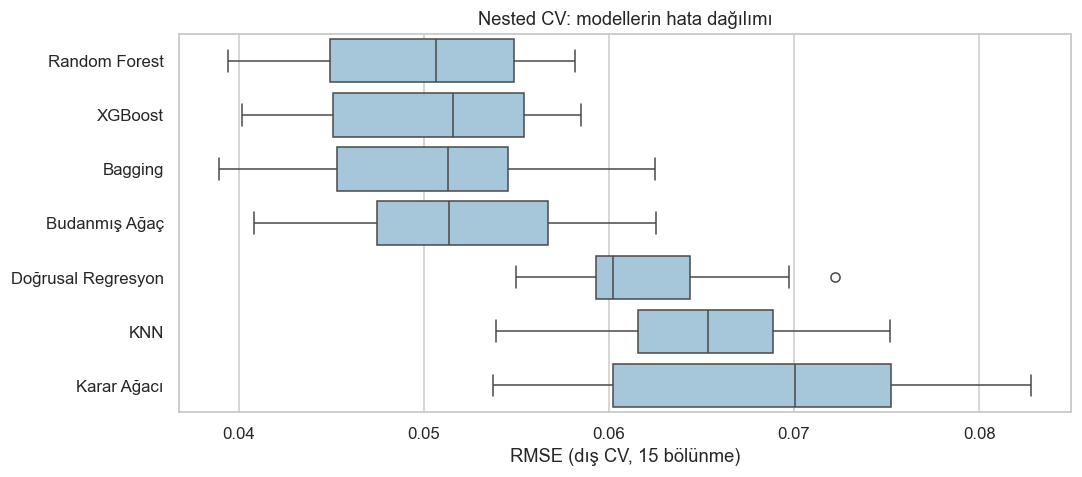

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.5))
sira = tablo.index.tolist()
sns.boxplot(data=pd.DataFrame({k: cv_sonuc[k]['rmse'] for k in sira}), orient='h', ax=ax, color='#9ecae1')
ax.set_xlabel('RMSE (dış CV, 15 bölünme)')
ax.set_title('Nested CV: modellerin hata dağılımı')
plt.tight_layout(); kaydet('cv_karsilastirma'); plt.show()

## 5. Test seti (tek sefer)

Her model tüm eğitim setinde yeniden ayarlanıp eğitiliyor ve test setinde bir kez değerlendiriliyor.
Belirsizliği göstermek için RMSE'ye 2000 tekrarlı bootstrap ile %95 güven aralığı ekliyorum.

In [14]:
rng = np.random.default_rng(SEED)
boot_idx = [rng.integers(0, len(y_test), len(y_test)) for _ in range(2000)]
y_te = y_test.to_numpy()

def rmse(a, b):
    return np.sqrt(mean_squared_error(a, b))

uydurulmus, tahmin, test_satirlari = {}, {}, []
for ad, model in modeller.items():
    m = model.fit(X_train, y_train)
    uydurulmus[ad] = m
    p = m.predict(X_test)
    tahmin[ad] = p
    boot = [rmse(y_te[i], p[i]) for i in boot_idx]
    test_satirlari.append({'Model': ad, 'Test RMSE': rmse(y_te, p),
                           '%95 GA alt': np.percentile(boot, 2.5), '%95 GA üst': np.percentile(boot, 97.5),
                           'Test MAE': mean_absolute_error(y_te, p), 'Test R²': r2_score(y_te, p)})

test_tablo = pd.DataFrame(test_satirlari).set_index('Model').loc[tablo.index]
test_tablo.insert(0, 'CV RMSE', tablo['CV RMSE'])
test_tablo

,CV RMSE,Test RMSE,%95 GA alt,%95 GA üst,Test MAE,Test R²
Random Forest,0.0500,0.0488,0.0391,0.0589,0.0365,0.8722
XGBoost,0.0503,0.0511,0.0420,0.0598,0.0400,0.8596
Bagging,0.0508,0.0514,0.0408,0.0625,0.0376,0.8580
Budanmış Ağaç,0.0520,0.0533,0.0421,0.0646,0.0397,0.8477
Doğrusal Regresyon,0.0617,0.0622,0.0544,0.0700,0.0508,0.7919
KNN,0.0650,0.0601,0.0508,0.0694,0.0472,0.8058
Karar Ağacı,0.0680,0.0721,0.0583,0.0853,0.0525,0.7208


In [15]:
for ad, m in uydurulmus.items():
    if hasattr(m, 'best_params_'):
        print(f'{ad:<15}', {k.replace('model__', ''): v for k, v in m.best_params_.items()})

KNN             {'n_neighbors': 5, 'weights': 'distance'}
Budanmış Ağaç   {'ccp_alpha': np.float64(0.00039810717055349735)}
Random Forest   {'max_features': 0.5, 'min_samples_leaf': 1}
XGBoost         {'learning_rate': 0.03, 'max_depth': 2, 'min_child_weight': 1, 'n_estimators': 200}


In [16]:
# En iyi model ile doğrusal regresyon arasındaki fark: eşleştirilmiş bootstrap
lm_p, best_p = tahmin['Doğrusal Regresyon'], tahmin[en_iyi]
farklar = np.array([rmse(y_te[i], lm_p[i]) - rmse(y_te[i], best_p[i]) for i in boot_idx])
print(f'RMSE(Doğrusal) - RMSE({en_iyi}) = {rmse(y_te, lm_p) - rmse(y_te, best_p):.4f}, '
      f'%95 GA [{np.percentile(farklar, 2.5):.4f}, {np.percentile(farklar, 97.5):.4f}], '
      f'P(fark <= 0) = {(farklar <= 0).mean():.3f}')

RMSE(Doğrusal) - RMSE(Random Forest) = 0.0135, %95 GA [0.0062, 0.0213], P(fark <= 0) = 0.000


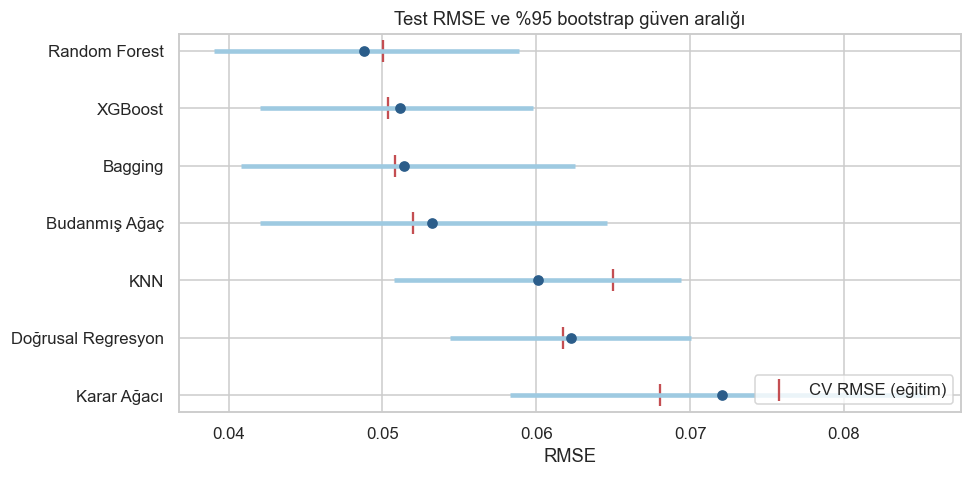

In [17]:
fig, ax = plt.subplots(figsize=(9, 4.5))
t = test_tablo.sort_values('Test RMSE', ascending=False)
ax.errorbar(t['Test RMSE'], t.index, xerr=[t['Test RMSE'] - t['%95 GA alt'], t['%95 GA üst'] - t['Test RMSE']],
            fmt='o', color='#2b5d8a', ecolor='#9ecae1', elinewidth=3, capsize=0)
ax.scatter(t['CV RMSE'], t.index, marker='|', s=200, color='#C44E52', label='CV RMSE (eğitim)')
ax.set_xlabel('RMSE'); ax.set_title('Test RMSE ve %95 bootstrap güven aralığı'); ax.legend(loc='lower right')
plt.tight_layout(); kaydet('model_karsilastirma'); plt.show()

## 6. En iyi model: hata analizi ve yorum

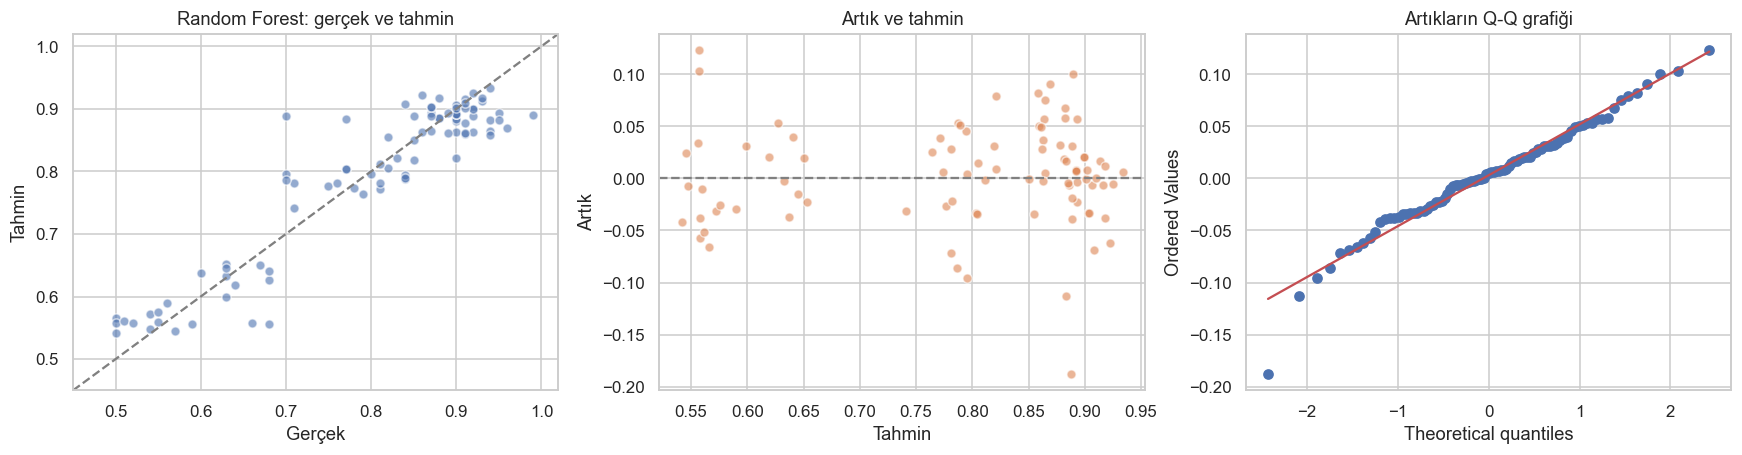

Artık ortalaması: 0.0030, std: 0.0490
|artık| > 0.10 olan gözlem: 5 / 91


In [18]:
artik = y_te - best_p
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
lim = [0.45, 1.02]
axes[0].scatter(y_te, best_p, alpha=0.6, color='#4C72B0', edgecolor='white')
axes[0].plot(lim, lim, '--', color='gray'); axes[0].set_xlim(lim); axes[0].set_ylim(lim)
axes[0].set_xlabel('Gerçek'); axes[0].set_ylabel('Tahmin'); axes[0].set_title(f'{en_iyi}: gerçek ve tahmin')
axes[1].scatter(best_p, artik, alpha=0.6, color='#DD8452', edgecolor='white')
axes[1].axhline(0, ls='--', color='gray'); axes[1].set_xlabel('Tahmin'); axes[1].set_ylabel('Artık')
axes[1].set_title('Artık ve tahmin')
stats.probplot(artik, dist='norm', plot=axes[2]); axes[2].set_title('Artıkların Q-Q grafiği')
plt.tight_layout(); kaydet('artik_analizi'); plt.show()

print(f'Artık ortalaması: {artik.mean():.4f}, std: {artik.std(ddof=1):.4f}')
print(f'|artık| > 0.10 olan gözlem: {(np.abs(artik) > 0.10).sum()} / {len(artik)}')

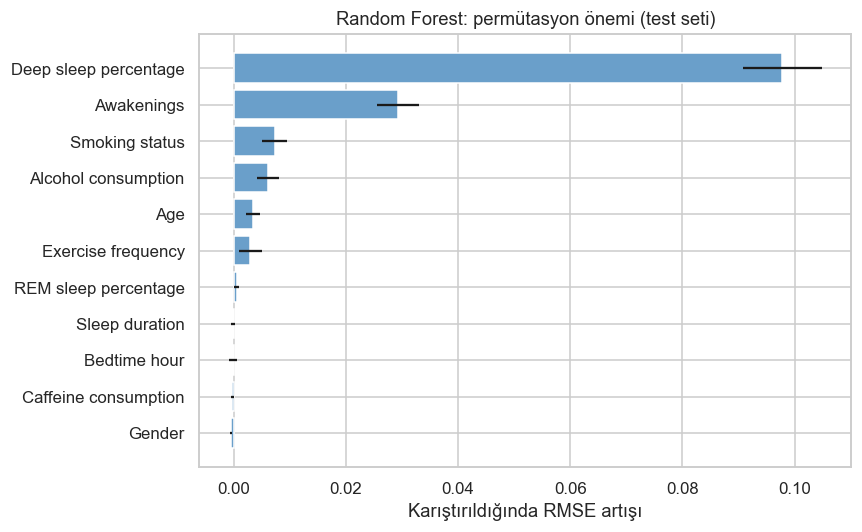

,ortalama,std
Deep sleep percentage,0.0978,0.0070
Awakenings,0.0293,0.0037
Smoking status,0.0073,0.0022
Alcohol consumption,0.0061,0.0020
Age,0.0035,0.0013
Exercise frequency,0.0030,0.0021
REM sleep percentage,0.0005,0.0004
Sleep duration,-0.0001,0.0003
Bedtime hour,-0.0001,0.0007
Caffeine consumption,-0.0002,0.0003


In [19]:
pi = permutation_importance(uydurulmus[en_iyi], X_test, y_test, n_repeats=50, random_state=SEED,
                            scoring='neg_root_mean_squared_error')
onem = pd.DataFrame({'ortalama': pi.importances_mean, 'std': pi.importances_std}, index=X_test.columns)
onem = onem.sort_values('ortalama')

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(onem.index, onem['ortalama'], xerr=onem['std'], color='#6a9fca')
ax.set_xlabel('Karıştırıldığında RMSE artışı'); ax.set_title(f'{en_iyi}: permütasyon önemi (test seti)')
plt.tight_layout(); kaydet('permutasyon_onemi'); plt.show()
onem.sort_values('ortalama', ascending=False)

Ağaç modellerinin `feature_importances_` değeri (impurity tabanlı) çok değer alan sürekli değişkenleri kayırma eğiliminde
ve eğitim verisi üzerinden hesaplanıyor. Bu yüzden önemi test setinde permütasyonla ölçtüm: bir değişken karıştırıldığında
hata ne kadar artıyorsa model o değişkene o kadar dayanıyor.

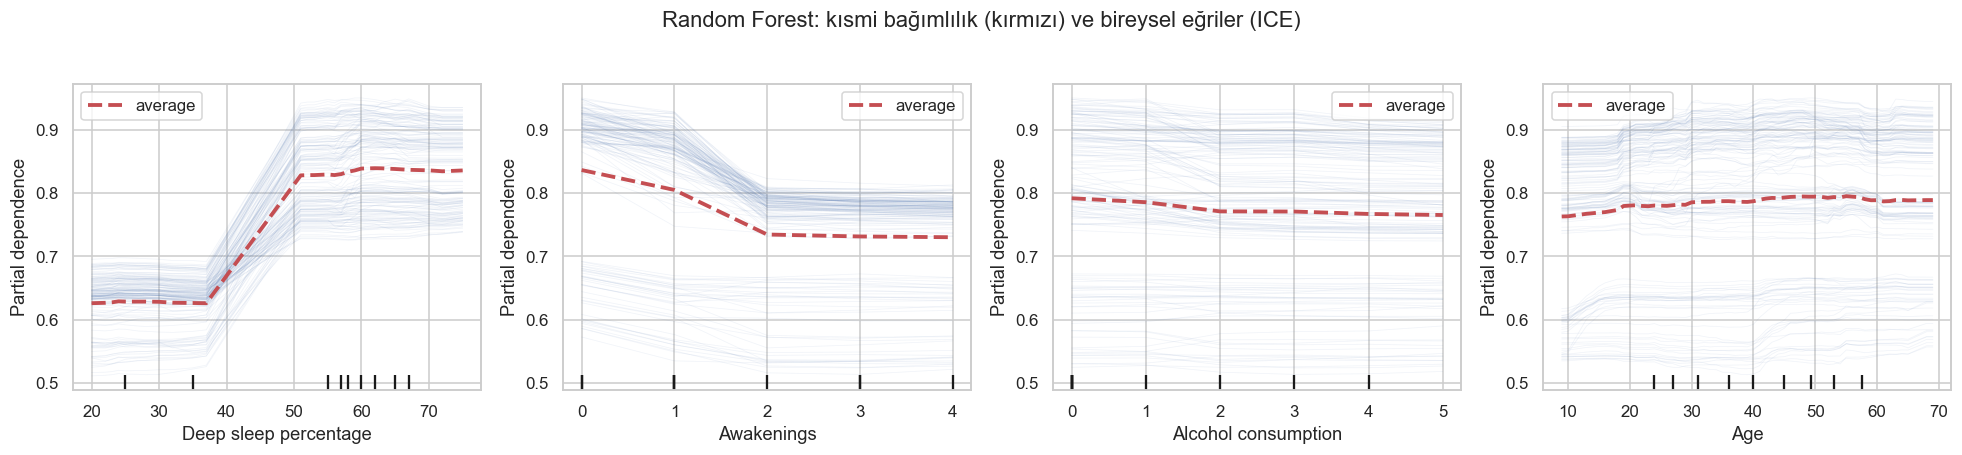

In [20]:
egri_ozellikleri = ['Deep sleep percentage', 'Awakenings', 'Alcohol consumption', 'Age']
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
PartialDependenceDisplay.from_estimator(uydurulmus[en_iyi], X_train, egri_ozellikleri, kind='both',
                                        subsample=150, random_state=SEED, ax=axes,
                                        ice_lines_kw={'alpha': 0.08, 'color': '#4C72B0'},
                                        pd_line_kw={'color': '#C44E52', 'lw': 2.5})
plt.suptitle(f'{en_iyi}: kısmi bağımlılık (kırmızı) ve bireysel eğriler (ICE)', y=1.03)
plt.tight_layout(); kaydet('kismi_bagimlilik'); plt.show()

## 7. Yaşam tarzı faktörleri: açıklayıcı model

Tahmin modelinde derin uyku ve uyanma sayısı baskın. Ama bunlar müdahale edilebilir faktörler değil; alkol veya egzersiz
uyku yapısını değiştirerek verimliliği etkiliyor olabilir. Bu durumda uyku yapısını modele eklemek, yaşam tarzının etkisinin
bir kısmını "emer" ve katsayılarını küçültür.

Bunu görmek için iki OLS modeli kurdum (tam veri, eksik gözlemler çıkarılmış, HC3 robust standart hata):

- **Model A:** demografi + yaşam tarzı + uyku zamanlaması
- **Model B:** Model A + uyku yapısı (derin uyku, REM, uyanma sayısı)

In [21]:
ols_df = df.rename(columns=lambda c: c.replace(' ', '_')).dropna()
print('Tam gözlem sayısı:', len(ols_df))

formul_a = ('Sleep_efficiency ~ Age + C(Gender) + C(Smoking_status) + Caffeine_consumption'
            ' + Alcohol_consumption + Exercise_frequency + Sleep_duration + Bedtime_hour')
formul_b = formul_a + ' + Deep_sleep_percentage + REM_sleep_percentage + Awakenings'

model_a = smf.ols(formul_a, data=ols_df).fit(cov_type='HC3')
model_b = smf.ols(formul_b, data=ols_df).fit(cov_type='HC3')
print(model_a.summary().tables[1])
print(f'Model A  R² = {model_a.rsquared:.3f}   düzeltilmiş R² = {model_a.rsquared_adj:.3f}')
print(f'Model B  R² = {model_b.rsquared:.3f}   düzeltilmiş R² = {model_b.rsquared_adj:.3f}')

Tam gözlem sayısı: 388
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept                    0.8528      0.099      8.618      0.000       0.659       1.047
C(Gender)[T.Male]           -0.0088      0.012     -0.727      0.467      -0.033       0.015
C(Smoking_status)[T.Yes]    -0.0699      0.015     -4.749      0.000      -0.099      -0.041
Age                          0.0017      0.001      3.251      0.001       0.001       0.003
Caffeine_consumption         0.0004      0.000      2.104      0.035    2.61e-05       0.001
Alcohol_consumption         -0.0320      0.004     -8.539      0.000      -0.039      -0.025
Exercise_frequency           0.0229      0.004      5.969      0.000       0.015       0.030
Sleep_duration              -0.0010      0.006     -0.155      0.877      -0.014       0.012
Bedtime_hour                -0.0046      0.004 

In [22]:
X_vif = model_b.model.exog
vif = pd.Series([variance_inflation_factor(X_vif, i) for i in range(1, X_vif.shape[1])],
                index=model_b.model.exog_names[1:], name='VIF')
bp = het_breuschpagan(model_a.resid, model_a.model.exog)
print(f'Breusch-Pagan (Model A): LM = {bp[0]:.2f}, p = {bp[1]:.4f}')
vif.round(2).to_frame()

Breusch-Pagan (Model A): LM = 50.52, p = 0.0000


,VIF
C(Gender)[T.Male],1.2700
C(Smoking_status)[T.Yes],1.1400
Age,1.1500
Caffeine_consumption,1.1300
Alcohol_consumption,1.2200
Exercise_frequency,1.2800
Sleep_duration,1.0300
Bedtime_hour,1.2500
Deep_sleep_percentage,1.4400
REM_sleep_percentage,1.1000


In [23]:
degiskenler = ['C(Smoking_status)[T.Yes]', 'Alcohol_consumption', 'Exercise_frequency',
               'Caffeine_consumption', 'Age', 'C(Gender)[T.Male]']
etiket = {'C(Smoking_status)[T.Yes]': 'Sigara (evet)', 'Alcohol_consumption': 'Alkol (birim)',
          'Exercise_frequency': 'Egzersiz (gün/hafta)', 'Caffeine_consumption': 'Kafein (mg)',
          'Age': 'Yaş (yıl)', 'C(Gender)[T.Male]': 'Erkek'}

def katsayi_tablosu(m, ad):
    ci = m.conf_int()
    return pd.DataFrame({'model': ad, 'katsayi': m.params[degiskenler], 'alt': ci.loc[degiskenler, 0],
                         'ust': ci.loc[degiskenler, 1], 'p': m.pvalues[degiskenler]})

kat = pd.concat([katsayi_tablosu(model_a, 'A: yaşam tarzı'), katsayi_tablosu(model_b, 'B: + uyku yapısı')])
kat_goster = kat.copy()
kat_goster.index = kat_goster.index.map(etiket)
kat_goster

,model,katsayi,alt,ust,p
Sigara (evet),A: yaşam tarzı,-0.0699,-0.0987,-0.0410,0.0000
Alkol (birim),A: yaşam tarzı,-0.0320,-0.0393,-0.0246,0.0000
Egzersiz (gün/hafta),A: yaşam tarzı,0.0229,0.0154,0.0305,0.0000
Kafein (mg),A: yaşam tarzı,0.0004,0.0000,0.0007,0.0353
Yaş (yıl),A: yaşam tarzı,0.0017,0.0007,0.0027,0.0012
Erkek,A: yaşam tarzı,-0.0088,-0.0327,0.0150,0.4674
Sigara (evet),B: + uyku yapısı,-0.0449,-0.0594,-0.0305,0.0000
Alkol (birim),B: + uyku yapısı,-0.0061,-0.0111,-0.0012,0.0147
Egzersiz (gün/hafta),B: + uyku yapısı,0.0058,0.0011,0.0106,0.0161
Kafein (mg),B: + uyku yapısı,0.0002,0.0000,0.0004,0.0146


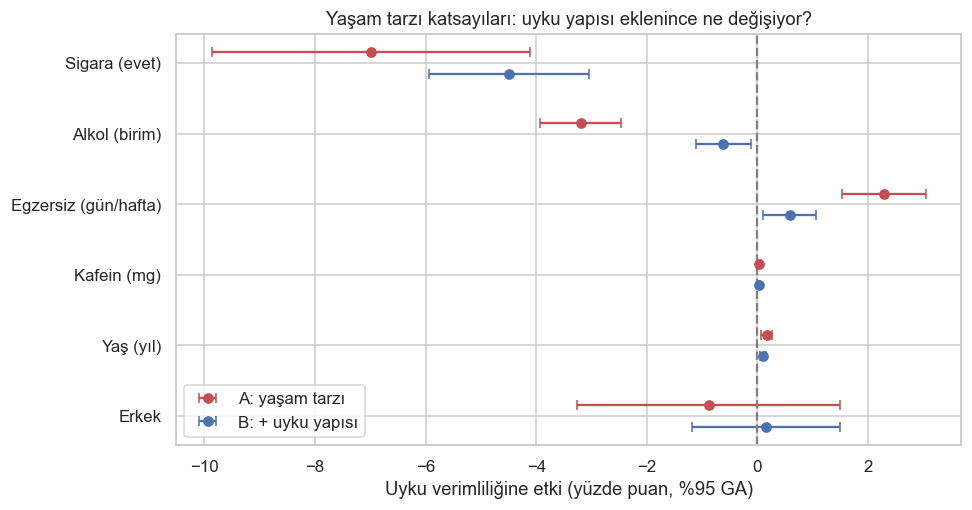

In [24]:
fig, ax = plt.subplots(figsize=(9, 4.8))
renk = {'A: yaşam tarzı': '#C44E52', 'B: + uyku yapısı': '#4C72B0'}
for j, (ad, g) in enumerate(kat.groupby('model', sort=False)):
    yk = np.arange(len(degiskenler)) + (j - 0.5) * 0.3
    # 0.01 birim = 1 yüzde puan
    ax.errorbar(g['katsayi'] * 100, yk, xerr=[(g['katsayi'] - g['alt']) * 100, (g['ust'] - g['katsayi']) * 100],
                fmt='o', color=renk[ad], label=ad, capsize=3)
ax.set_yticks(range(len(degiskenler))); ax.set_yticklabels([etiket[d] for d in degiskenler])
ax.axvline(0, color='gray', ls='--'); ax.invert_yaxis()
ax.set_xlabel('Uyku verimliliğine etki (yüzde puan, %95 GA)')
ax.set_title('Yaşam tarzı katsayıları: uyku yapısı eklenince ne değişiyor?')
ax.legend(loc='lower left')
plt.tight_layout(); kaydet('yasam_tarzi_katsayilar'); plt.show()

In [25]:
# Duyarlılık: eksikleri silmek yerine medyanla doldurunca sonuç değişiyor mu?
dolu = df.rename(columns=lambda c: c.replace(' ', '_')).copy()
for c in ['Awakenings', 'Caffeine_consumption', 'Alcohol_consumption', 'Exercise_frequency']:
    dolu[c] = dolu[c].fillna(dolu[c].median())
model_a_dolu = smf.ols(formul_a, data=dolu).fit(cov_type='HC3')
pd.DataFrame({'tam gözlem (n=%d)' % len(ols_df): model_a.params[degiskenler],
              'medyan doldurma (n=%d)' % len(dolu): model_a_dolu.params[degiskenler]}).rename(index=etiket)

,tam gözlem (n=388),medyan doldurma (n=452)
Sigara (evet),-0.0699,-0.0724
Alkol (birim),-0.0320,-0.0304
Egzersiz (gün/hafta),0.0229,0.0224
Kafein (mg),0.0004,0.0003
Yaş (yıl),0.0017,0.0012
Erkek,-0.0088,-0.0015


In [26]:
# Yaşam tarzı tek başına ne kadar tahmin gücü taşıyor? (eğitim setinde CV, uyku yapısı hariç)
yasam_sutun = DEMOGRAFIK + YASAM + ZAMAN
yasam_pipe = Pipeline([('pre', ColumnTransformer([
                          ('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]),
                           [c for c in yasam_sutun if c not in KATEGORIK]),
                          ('cat', OneHotEncoder(drop='if_binary'), KATEGORIK)])),
                       ('model', LinearRegression())])
r2_yasam = cross_validate(yasam_pipe, X_train[yasam_sutun], y_train, cv=dis_cv, scoring='r2')['test_score']
print(f'Yalnızca yaşam tarzı + demografi, CV R² = {r2_yasam.mean():.3f} ± {r2_yasam.std():.3f}')
print(f"Tüm değişkenler ({en_iyi}), CV R² = {cv_sonuc[en_iyi]['r2'].mean():.3f}")

Yalnızca yaşam tarzı + demografi, CV R² = 0.241 ± 0.106
Tüm değişkenler (Random Forest), CV R² = 0.857


## 8. Sonuçlar

**Tahmin**

- Topluluk modelleri (Random Forest, XGBoost, Bagging) ve budanmış ağaç nested CV'de RMSE ≈ 0.050–0.052 ile başabaş;
  aralarındaki farklar düzeltilmiş t-testinde anlamlı değil (p > 0.4). Random Forest test setinde RMSE = 0.049 (%95 GA 0.039–0.059), R² = 0.87.
- Doğrusal regresyon belirgin şekilde geride (CV RMSE 0.062, p < 0.001). Test setinde de fark güven aralığı sıfırı içermiyor
  (0.006–0.021). Sebep doğrusal olmayan ilişkiler: uyanma sayısı ve derin uyku yüzdesinin etkisi eşik benzeri, PDP grafiklerinde bu açıkça görülüyor.
- Tamamen büyümüş tek ağaç en kötü model; budama tek başına hatayı %24 düşürüyor.
- Tahmin gücünün neredeyse tamamı iki değişkenden geliyor: **derin uyku yüzdesi** ve **gece uyanma sayısı**.

**Yaşam tarzı (açıklayıcı model, n = 388, HC3 robust SE)**

- Diğer değişkenler sabitken, her ek alkol birimi uyku verimliliğinde ortalama **3.2 puanlık** düşüşle, sigara içmek **7.0 puanlık** düşüşle,
  haftada bir gün fazla egzersiz **2.3 puanlık** artışla ilişkili. Hepsi p < 0.001 ve medyan doldurma ile yapılan duyarlılık analizinde neredeyse aynı.
- Uyku yapısı modele eklendiğinde alkolün katsayısı 3.2'den 0.6 puana, egzersizinki 2.3'ten 0.6 puana iniyor. Bu, alkol ve egzersizin
  verimlilikle ilişkisinin büyük kısmının derin uyku ve uyanma üzerinden geçtiğiyle tutarlı. Sigaranın katsayısı ise 7.0'dan 4.5'e iniyor,
  yani sigaranın uyku yapısıyla açıklanamayan bir ilişkisi de var.
- Kafeinin küçük ama pozitif katsayısı sezgiye ters; kafein tüketimi ölçülmemiş başka faktörlerle (ör. çalışma düzeni) ilişkili olabilir. Bu katsayıyı yorumlamıyorum.
- Yaşam tarzı ve demografi tek başına verimliliğin yalnızca ~%24'ünü açıklıyor (CV R²). Tahmin için uyku yapısı ölçümleri şart.

**Sınırlılıklar**

- Kesitsel ve gözlemsel veri: katsayılar ilişkiyi gösteriyor, nedenselliği değil. Katsayı değişimine dayanan "aracılık" yorumu da
  ancak ölçülmemiş karıştırıcı olmadığı varsayımıyla geçerli.
- Her katılımcı için tek gece ölçüm var; bireyin olağan uyku düzenini temsil etmeyebilir.
- Model A'da Breusch-Pagan testi heteroskedastisiteyi doğruluyor (p < 0.001); bu yüzden tüm çıkarımlarda HC3 standart hata kullandım.
  Hedef 0–1 aralığında sınırlı olduğu için beta regresyonu bir sonraki adım olabilir.